<a href="https://colab.research.google.com/github/ikwak2/bio_sig_class/blob/main/03_ecg_cnn_augmentation_teaching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습 3. 1D·2D CNN, 데이터 증강과 최고 모델 앙상블

1D CNN은 BatchNorm·MaxPool 구조, 2D CNN은 GroupNorm을 사용하는 세 블록 구조입니다. 단일 모델의 증강 전후 성능을 비교한 뒤, **검증 AP 평균으로 선택한 각 표현의 최고 조건**을 확률 평균 앙상블로 결합합니다.

특징 기반 ML 실습과 동일한 MIT-BIH ECG의 30초 창에서 전문가 V 주석 포함 여부를 예측합니다. 전문가 주석은 정답 생성과 설명에만 사용합니다.


In [1]:
# Colab에서 필요한 ECG 읽기 도구 wfdb를 설치합니다.
# %pip는 현재 노트북의 Python 환경에 설치하는 명령입니다.
%pip install -q wfdb


## 1. 실험 조건

1D 3조건(무증강·진폭 조절·시간 이동), 2D 5조건(무증강·Cutout·SpecAugment·시간 이동·crop)을 각각 3 seed로 학습합니다. **8조건 × 3 seed = 24회 학습**입니다.

각 표현에서 **3 seed의 검증 AP 평균이 가장 높은 증강 조건** 하나를 선택합니다. 동률이면 미리 정한 실험 순서를 따릅니다. 선택한 1D와 2D 조건의 같은 seed끼리 확률을 0.5씩 평균하여 3개 앙상블을 평가합니다. 평균 가중치는 고정하며 검증 BAcc로 임계값만 선택합니다.

환자 분할·조건 선택·임계값을 고정한 뒤 시험 자료를 평가합니다. 시험 점수로 최고 모델이나 가중치를 고르지 않습니다. 이미 확인한 교육용 분할을 수정한 예제이므로 새로운 독립 시험을 대체하지 않습니다.

**이 실습의 세 단계 선택:** (1) 실행마다 validation AP로 epoch를 고르고, (2) 표현마다 세 seed의 평균 validation AP로 증강 조건을 고른 뒤, (3) 고정한 조건의 모델을 test에서 비교합니다. 24회는 서로 다른 환자 분할 24개가 아니라 **8조건×같은 세 seed**입니다.


In [2]:
# 이 셀은 도구 불러오기와 공통 설정입니다. 아래 실험들은 이 값을 함께 사용합니다.
# 코드의 B는 배치 크기, L은 시간 샘플 수, F/T는 스펙트로그램의 주파수/시간 축으로 읽으면 됩니다.
# Path: 파일 경로를 운영체제에 맞게 다룹니다. 아래 OUT 폴더에 실행 결과가 모입니다.
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import copy, hashlib, json, platform, random, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# signal: 필터·resampling에 사용합니다. wfdb: ECG 파형과 전문가 박동 주석을 읽습니다.
from scipy import signal
import wfdb
import torch
from torch import nn
# Dataset은 구간 하나를 꺼내고, DataLoader는 여러 구간을 묶어 배치를 만듭니다.
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (average_precision_score, roc_auc_score, balanced_accuracy_score,
    f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT/'data'/'mitdb'
OUT = ROOT/'results'/'ecg_cnn_ensemble'
OUT.mkdir(parents=True,exist_ok=True)
# 같은 기록의 겹치는 구간이 train과 test에 동시에 들어가지 않도록 기록 번호로 분할합니다.
SPLITS = {'train':['100','101','103','106','108','119'],
          'val':['105','112','200'], 'test':['117','203','208']}
# 원본 초당 360개 값을 초당 128개로 변환합니다. 30초 입력 길이는 128×30=3840입니다.
ORIGINAL_FS, FS = 360, 128
# 30초 창을 15초씩 옮깁니다. 이웃한 창은 15초가 겹치므로 서로 독립 표본은 아닙니다.
WINDOW_S, HOP_S = 30, 15
# 같은 데이터 분할에서 초기화·최적화의 무작위성을 세 번 반복합니다. 환자 분할을 세 번 바꾸는
# 것은 아닙니다.
SEEDS = [11,22,33]
# 각 실행은 8 epoch, 미니배치 32개 구간, 학습률 0.001입니다. 8조건×3 seed=총24회 학습합니다.
EPOCHS, BATCH_SIZE, LEARNING_RATE = 8, 32, .001
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4,torch.get_num_threads()))
# V 포함 여부를 예측합니다. 다른 부정맥을 정상이라고 부르지 않습니다.
# 실험 설정을 사전(dict)으로 모아 둡니다. 마지막에 JSON과 checkpoint로 저장해 입력 처리 조건을
# 남깁니다.
CONFIG = {'splits':SPLITS,'fs':FS,'window_s':WINDOW_S,'hop_s':HOP_S,
          'epochs':EPOCHS,'seeds':SEEDS,'batch_size':BATCH_SIZE,'lr':LEARNING_RATE,
          'label':'any expert V in [start,end)', 'data_version':'mitdb1.0.0',
          'augmentation_probability':.7,'amplitude_gain_range':[0.9,1.3],'code_version':'amplitude09-13-best-ensemble-v6'}
print('Device:',DEVICE,'/ seeds:',SEEDS,'/ epochs:',EPOCHS)
# 여기서 channel/width는 CNN 필터 개수입니다. ECG를 8·16·32채널로 측정했다는 뜻이 아닙니다.
CONFIG.update({'normalization':'per-window waveform zscore + per-window logspec zscore',
               'n_fft':256,'hop':64,'fmin':.5,'fmax':40,'center':True,
               'norm':{'1D':'BatchNorm1d','2D':'GroupNorm4'},
               'widths':{'1D':[8,16,24],'2D':[8,16,32]},'ensemble':'validation-mean-AP selection; probability mean 0.5/0.5'})


Device: cuda / seeds: [11, 22, 33] / epochs: 8


## 2. 데이터와 전처리

**12명·1,428개 창**, train 714 / val 357 / test 357을 유지합니다. 환자별 분할, 30초 창·15초 hop, y=1은 구간 안의 V 주석 하나 이상입니다. y=0은 정상 환자라는 뜻이 아닙니다.

ECG에는 0.5–40Hz 양방향 필터를 적용하고 360→128Hz로 resampling합니다. 원 코드의 EEG 대역 0.1–45Hz를 그대로 가져오지 않습니다. 양방향 필터는 오프라인 조건입니다.

**참고 코드처럼 구간별 정규화**합니다. 각 파형의 평균을 빼고 자체 표준편차로 나눈 뒤 ±20으로 clip합니다. STFT도 각 구간의 log power 평면 자체의 평균·표준편차로 표준화합니다. 검증·시험의 여러 구간을 한꺼번에 모아 통계를 맞추는 방식이 아닙니다. 구간별 계산은 추론에서도 가능합니다.

이 방식은 원래 진폭과 절대 파워 정보를 줄이는 선택입니다. 모든 생체신호 과제에 항상 더 좋은 것은 아닙니다.

STFT: n_fft=256(2초), hop=64(0.5초), Hann, center=True, reflect padding. ECG 관심 대역 0.5–40Hz를 선택해 **80×61** 수치 행렬을 만듭니다. EEG 원 코드의 0.5–45Hz는 90×61입니다. 양 끝 프레임에는 반사 패딩의 영향이 있습니다. 파워 스펙트로그램은 위상 정보를 버리므로 원파형과 완전히 같은 정보를 보존하지 않습니다.

In [3]:
# Python·NumPy·PyTorch의 난수를 같은 seed로 시작합니다. 같은 표현/seed의 조건들을 비교하기 위한
# 설정입니다.
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    # 가능한 범위에서 GPU 연산을 반복 가능하게 합니다. 서로 다른 하드웨어/버전까지 동일 수치를
    # 보장하는 설정은 아닙니다.
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False

# hea는 신호 설명, dat는 파형, atr은 박동 주석입니다. 이미 받은 파일은 재사용합니다.
def download_record(record):
    DATA.mkdir(parents=True,exist_ok=True)
    for ext in ['hea','dat','atr']:
        p=DATA/f'{record}.{ext}'
        if not p.exists():
            # 다운로드가 중단된 파일을 완성 파일로 오인하지 않도록 임시 이름으로 받은 뒤
            # 바꿉니다.
            tmp=p.with_suffix(p.suffix+'.part')
            try:
                with urllib.request.urlopen(f'https://physionet.org/files/mitdb/1.0.0/{p.name}',timeout=90) as response:
                    tmp.write_bytes(response.read())
                tmp.replace(p)
            finally: tmp.unlink(missing_ok=True)
    return record



# STFT는 고정된 수학 변환입니다. 이 클래스에는 학습할 CNN 가중치가 없습니다.
class SpectrogramFrontEnd(nn.Module):
    """참고 코드의 torch.stft + 구간별 log-power z-score를 ECG용으로 조정."""
    def __init__(self):
        super().__init__()
        # Hann 창을 buffer로 등록하면 학습 파라미터에는 포함되지 않으면서 .to(DEVICE) 때 함께
        # 이동합니다.
        self.register_buffer('window',torch.hann_window(256))
        # 256점 FFT의 주파수 간격은 FS/n_fft=128/256=0.5 Hz입니다. 전체 one-sided 범위는 0~64
        # Hz입니다.
        f=torch.fft.rfftfreq(256,d=1/FS)
        # 0.5~40 Hz만 선택합니다. 0.5 Hz 간격으로 80개 bin이며 DC(0 Hz)는 제외합니다.
        self.register_buffer('bins',torch.where((f>=.5)&(f<=40))[0])
    def forward(self,x):
        # 입력 x는 [B,C,L]. 이 실습은 C=1, L=3840입니다.
        b,c,l=x.shape
        # STFT가 처리하기 쉽게 B와 C를 합칩니다. 출력 z는 복소수 [B*C,주파수,프레임]입니다.
        # 256샘플=2초 창, hop64샘플=0.5초 간격. center=True에서는 30초 신호에 61개 프레임이
        # 나옵니다.
        z=torch.stft(x.reshape(b*c,l),n_fft=256,hop_length=64,
            window=self.window,center=True,pad_mode='reflect',return_complex=True)
        # abs²는 파워, log10은 큰 파워와 작은 파워의 차이를 압축합니다. 1e-10은 log(0)을
        # 막습니다.
        # index_select(1, bins)는 주파수 축에서 관심 대역만 꺼냅니다. RGB 이미지를 만드는 과정은
        # 아닙니다.
        logp=torch.log10(z.abs().square().index_select(1,self.bins)+1e-10)
        # 다시 [B,C,80,61]로 복원합니다. 한 구간의 log-power 평면은 주파수×시간 배열입니다.
        logp=logp.reshape(b,c,len(self.bins),-1)
        # 마지막 두 축(F,T)에 대해 각 구간/채널 자체의 평균·표준편차를 계산합니다.
        # keepdim=True는 뺄셈·나눗셈 때 broadcasting할 수 있도록 크기 1인 축을 남깁니다.
        mu=logp.mean((-2,-1),keepdim=True)
        sd=logp.std((-2,-1),keepdim=True).clamp_min(1e-4)
        return (logp-mu)/sd

# FRONT는 장치로 옮긴 변환기입니다. 아래 spectrum()은 입력을 미리 계산하기 위해 별도 변환기를
# 사용합니다.
FRONT=SpectrogramFrontEnd().to(DEVICE).eval()

# 마지막 시간 축만 정규화하므로 일반 구간 [N,L]과 crop 후보 [N,5,L] 모두 처리할 수 있습니다.
def standardize_wave(x):
    mu=x.mean(axis=-1,keepdims=True)
    # 거의 평평한 구간에서 너무 작은 표준편차로 나누지 않도록 하한을 둡니다.
    sd=np.maximum(x.std(axis=-1,keepdims=True),1e-4)
    # 극단적인 표준화 값을 ±20으로 제한합니다. 반환 파형은 원래 mV가 아니라 z-score 값입니다.
    return np.clip((x-mu)/sd,-20,20).astype('float32')

# 출력은 입력의 앞쪽 모양을 유지하고 끝에 [80,61]을 붙입니다. 예: [N,L]→[N,80,61].
def spectrum(x):
    # 임의의 앞쪽 차원을 지원하고, CPU에서 작은 배치로 미리 계산합니다.
    # 앞쪽 모양을 기억한 뒤 시간 축 외의 축을 합칩니다. crop이면 N×5개의 신호를 일렬로
    # 처리합니다.
    shape=x.shape[:-1];flat=np.asarray(x,dtype='float32').reshape(-1,x.shape[-1])
    front=SpectrogramFrontEnd().eval();out=[]
    # 미리 특징을 만드는 단계라 gradient를 기록하지 않습니다. 작은 배치로 나눠 메모리 사용을
    # 줄입니다.
    with torch.no_grad():
        for start in range(0,len(flat),64):
            out.append(front(torch.from_numpy(flat[start:start+64,None,:])).numpy()[:,0])
    return np.concatenate(out).reshape(*shape,80,61)

# 반환값: split별 입력/정답 배열, 구간 설명표(meta), 정규화 설정, 기록별 파형, V 시각입니다.
def build_data():
    # 분할표의 기록 번호를 한 리스트로 합치고 중복 여부를 확인합니다.
    records=sum(SPLITS.values(),[])
    assert len(records)==len(set(records))
    with ThreadPoolExecutor(max_workers=4) as pool:
        list(pool.map(download_record,records))
    # raw/spec와 정답은 같은 행 순서를 유지해야 합니다. crop 후보도 입력과 라벨을 함께
    # 저장합니다.
    signals={}; v_times={}; rows=[]; raw=[]; crop_raw=[]; crop_y=[]
    # window 폭은 3840샘플입니다. crop은 길이를 줄이는 대신 시작점을 바꾼 30초 구간을 만듭니다.
    width=WINDOW_S*FS
    # 다섯 후보 시작점은 원래 시작점에서 -1, -0.5, 0, +0.5, +1초입니다.
    offsets=np.array([-FS,-FS//2,0,FS//2,FS])
    # 원본 360 Hz에서 0.5~40 Hz의 4차 bandpass 필터를 설계합니다. sos는 수치적으로 안정적인
    # 표현입니다.
    sos=signal.butter(4,[.5,40],btype='bandpass',fs=ORIGINAL_FS,output='sos')
    for split,recs in SPLITS.items():
        for record in recs:
            # 파형과 전문가 주석을 따로 읽습니다. 주석은 정답에만 사용하고 CNN 입력에는 넣지
            # 않습니다.
            rec=wfdb.rdrecord(str(DATA/record)); ann=wfdb.rdann(str(DATA/record),'atr')
            # MLII 채널을 우선 선택하고, 이름이 없으면 첫 채널을 선택하는 코드입니다.
            lead=rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
            assert rec.fs==ORIGINAL_FS and rec.units[lead]=='mV'
            # 기록 전체를 양방향 필터링한 뒤 창을 나눕니다. 미래 시점도 이용하는 오프라인
            # 처리입니다.
            x=signal.sosfiltfilt(sos,rec.p_signal[:,lead])
            # 128/360=16/45로 샘플 수를 바꿉니다. 이 함수에는 anti-aliasing을 위한 필터링도
            # 포함됩니다.
            x=signal.resample_poly(x,16,45).astype(np.float32)
            # 주석의 sample 번호는 원본 360 Hz 기준입니다. 초 단위로 바꾸면 resampling 후 구간과
            # 비교할 수 있습니다.
            vt=np.asarray(ann.sample)[np.asarray(ann.symbol)=='V']/ORIGINAL_FS
            signals[record]=x;v_times[record]=vt
            # 시작 sample에서 30초 동안 V가 하나라도 있으면 1입니다. 범위는 [시작,끝)이므로 끝
            # 시점은 제외합니다.
            def label(start):return float(np.any((vt>=start/FS)&(vt<(start+width)/FS)))
            # 한 창마다 raw 입력 하나와 target 하나를 생성합니다. 실제 정답 단위는 박동이 아니라
            # 30초 구간입니다.
            for start in range(0,len(x)-width+1,HOP_S*FS):
                raw.append(x[start:start+width])
                yy=label(start)
                rows.append({'record':record,'split':split,'start_s':start/FS,
                             'end_s':(start+width)/FS,'target':int(yy)})
                # 주변 문맥에서 30초를 다시 자르고, V 포함 여부에 따라 y도 갱신합니다.
                # crop 후보는 train에만 만듭니다. np.clip은 후보가 기록 경계 밖으로 나가지 않게
                # 시작점을 제한합니다.
                # 기록의 양 끝에서는 서로 다른 offset이 같은 실제 시작점으로 겹칠 수 있습니다.
                if split=='train':
                    starts=np.clip(start+offsets,0,len(x)-width)
                    crop_raw.append(np.stack([x[s:s+width] for s in starts]))
                    crop_y.append([label(s) for s in starts])
            print('Prepared record',record,flush=True)
    meta=pd.DataFrame(rows)
    # 전체 raw의 모양은 [1428,1,3840]. None으로 물리적 ECG 채널 축 1개를 추가합니다.
    raw=standardize_wave(np.stack(raw))[:,None,:]
    # raw[:,0]에서 불필요한 채널 축을 잠시 빼 STFT를 계산하고, 다시 [1428,1,80,61]로 만듭니다.
    spec=spectrum(raw[:,0])[:,None,:,:]
    norm={'waveform':'per-window zscore then clip +-20',
          'spectrogram':'per-window/channel logpower zscore',
          'n_fft':256,'hop':64,'fmin':.5,'fmax':40,'center':True}
    # 훈련 crop은 [714,5,3840]입니다. 후보 구간마다 자체 평균·표준편차로 정규화합니다.
    crop_raw=standardize_wave(np.stack(crop_raw))
    # 각 후보의 STFT도 함께 계산해 [714,5,1,80,61]로 저장합니다.
    crop_spec=spectrum(crop_raw)[:,:,None,:,:]
    arrays={}
    # 같은 mask로 raw/spec/y/meta를 나눠 같은 행이 같은 구간을 가리키게 합니다.
    for split in SPLITS:
        mask=meta.split.eq(split).to_numpy()
        arrays[split]={'raw':raw[mask].astype('float32'),'spec':spec[mask].astype('float32'),
                       'y':meta.loc[mask,'target'].to_numpy(dtype='float32'),
                       'meta':meta.loc[mask].reset_index(drop=True)}
    # Dataset이 후보 j를 고르면 crop_raw[i,j], crop_spec[i,j], crop_y[i,j]를 함께 반환합니다.
    arrays['train']['crop_raw']=crop_raw[:,:,None,:].astype('float32')
    arrays['train']['crop_spec']=crop_spec.astype('float32')
    arrays['train']['crop_y']=np.asarray(crop_y,dtype='float32')
    # 예상한 입력 모양과 crop-라벨 정렬이 맞는지 검사합니다. assert는 학습 기능이 아니라 확인
    # 장치입니다.
    assert raw.shape[1:]==(1,3840) and spec.shape[1:]==(1,80,61)
    assert arrays['train']['crop_spec'].shape[:2]==arrays['train']['crop_y'].shape
    return arrays,meta,norm,signals,v_times


### 구간별 정규화와 입력 확인

파형 `[B,1,3840]`, 스펙트로그램 `[B,1,80,61]`입니다. 같은 행의 두 입력은 반드시 같은 환자·같은 30초 구간에서 나옵니다. crop 후보도 파형·스펙트로그램·y를 함께 묶어 관리합니다. CNN 입력에는 박동 주석을 넣지 않습니다.

| 배열 | 모양 | 한 행의 뜻 |
|---|---|---|
| 일반 raw | `[N,1,3840]` | 한 기록의 30초 파형 |
| 일반 spec | `[N,1,80,61]` | 같은 30초 구간의 주파수×시간 표현 |
| train crop_raw | `[714,5,1,3840]` | 원래 훈련 구간마다 다섯 시작점 후보 |
| train crop_spec | `[714,5,1,80,61]` | 각 crop 후보에 대응하는 STFT |
| train crop_y | `[714,5]` | 각 후보에서 다시 계산한 정답 |

`N`은 train/val/test의 구간 수입니다. `1`은 실제 ECG 채널 수이며 CNN 내부의 필터 수와 구분합니다. 128 Hz×30초=3,840개 값이고, STFT의 주파수 간격 0.5 Hz와 시간 간격 0.5초는 서로 다른 축의 단위입니다.


In [4]:
# 위에서 정의한 전처리를 실제 실행합니다. arrays의 train/val/test에 입력과 정답이 함께 들어
# 있습니다.
arrays,meta,norm,signals,v_times=build_data()
print('Raw:',arrays['train']['raw'].shape,'/ Spectrogram:',arrays['train']['spec'].shape)
# 기록마다 창 수, 양성 창 수, 양성 비율을 확인합니다. positive는 V 박동 수가 아니라 V 포함 창
# 수입니다.
display(meta.groupby(['split','record']).target.agg(windows='size',positive='sum',positive_rate='mean'))
# 이 실습의 전체 train/val/test에는 각각 양성과 음성이 모두 있어야 두 클래스 평가가 가능합니다.
for split in SPLITS: assert len(np.unique(arrays[split]['y']))==2, f'{split}: 두 클래스가 필요합니다.'
# 어떤 기록의 어느 시각을 사용했는지 저장합니다. index=False는 불필요한 행 번호 열을 쓰지 않는
# 설정입니다.
meta.to_csv(OUT/'window_manifest.csv',index=False)


Prepared record 100
Prepared record 101
Prepared record 103
Prepared record 106
Prepared record 108
Prepared record 119
Prepared record 105
Prepared record 112
Prepared record 200
Prepared record 117
Prepared record 203
Prepared record 208
Raw: (714, 1, 3840) / Spectrogram: (714, 1, 80, 61)


windows  positive  positive_rate
split record                                  
test  117         119         0       0.000000
      203         119       119       1.000000
      208         119       118       0.991597
train 100         119         2       0.016807
      101         119         0       0.000000
      103         119         0       0.000000
      106         119        76       0.638655
      108         119        33       0.277311
      119         119       116       0.974790
val   105         119        62       0.521008
      112         119         0       0.000000
      200         119       117       0.983193

## 3. 증강 함수와 라벨 처리

### Raw 파형 진폭 조절 (amplitude scaling)

각 30초 파형마다 하나의 양수 계수 $a \sim U(0.9,1.3)$를 뽑아 **모든 시점에 동일하게** 곱합니다.

$$\tilde x[t]=a\,x[t],\qquad \tilde y=y.$$

예를 들어 a=1.3이면 모든 진폭이 30% 커집니다. 진폭의 상대적인 모양·부호·박동 시점·RR 간격은 그대로이고, RMS는 a배가 됩니다. 시점마다 다른 계수를 곱하는 잡음과 구분합니다. 다른 환자의 입력이나 정답을 섞지 않습니다.

이 실습은 **최대 10% 축소부터 최대 30% 확대까지** 적용합니다. 학습 배치마다 확률0.7로 적용하고, 적용할 때는 배치 내 파형마다 다른 계수를 뽑습니다. 2D 모델에는 적용하지 않습니다.

**적용 순서가 중요합니다:** 구간별 표준화 → 진폭 조절 → 1D CNN. 확대 뒤에 구간별 z-score를 다시 하면 양수 배율이 상쇄되므로 재표준화하지 않습니다. 따라서 표준화된 입력의 gain 변화에 대한 강건성을 학습하는 실험이며, 물리적 mV 자체를 보존하는 실험은 아닙니다.

### 시간 shifting

1D는 최대 ±0.5초, 2D는 최대 ±1프레임(0.5초) 이동합니다. 원형 이동(`roll`)을 사용해 모든 입력 값을 유지하고 라벨은 유지합니다. 끝부분이 앞으로 돌아오는 **인위적인 접합부**가 생깁니다. 2D에서 주파수축 이동은 하지 않습니다. 주파수 이동은 다른 생리적 주파수를 뜻하기 때문입니다.

### Cutout

12개 주파수 빈 × 6개 시간 프레임(약 6Hz × 3초)의 직사각형을 평균값 0으로 가리고 라벨을 유지합니다. 유일한 V 정보를 가릴 수 있으므로 성능이 악화될 가능성도 함께 확인합니다. 다른 예시의 영역을 붙이거나 면적 비율로 라벨을 섞지 않습니다.

### 간소화 SpecAugment

최대 4Hz 폭의 주파수 띠, 최대 1초의 시간 띠를 각각 하나 가립니다. 원 논문의 time warping은 구현하지 않은 **time/frequency masking 버전**입니다. 가림 값 0은 각 구간의 log power를 표준화한 평균입니다. 원 신호의 무신호나 물리적 0파워를 의미하지 않습니다.

### 시간 crop

주변 문맥에서 시작 위치를 바꾼 30초 구간을 다시 잘라 STFT를 계산합니다. 빈 영역을 늘리거나 주파수축을 임의 resize하지 않습니다. crop으로 V가 들어오거나 빠지면 **그 새 구간의 주석으로 y를 다시 계산**합니다. 이 라벨 생성에는 훈련 주석만 사용합니다.

**코드에서 확인할 적용 단위:** `apply_augmentation()`의 0.7 확률은 배치 전체에 대해 한 번 정합니다. 적용하기로 한 배치 안에서는 진폭 계수와 shift 크기를 샘플마다 따로 뽑습니다. Cutout의 사각형 위치는 배치가 공유하며, SpecAugment의 띠는 샘플마다 따로 뽑습니다.

Crop은 이 확률 게이트의 대상이 아닙니다. `ECGDataset(..., crop=True)`가 매 샘플에서 다섯 후보 중 하나를 고릅니다. 후보에는 원래 위치도 있으므로 crop 조건에서도 원래 창을 받을 수 있습니다.


In [5]:
# 원본 tensor를 바꾸지 않도록 복사하고, 각 샘플의 시간 축만 원형 이동합니다.
def circular_shift(x,max_shift,rng):
    result=x.clone()
    for i in range(len(x)):
        # integers의 상한은 제외되므로 +1을 써서 -max_shift와 +max_shift를 모두 포함합니다.
        shift=int(rng.integers(-max_shift,max_shift+1))
        # dims=-1은 마지막 축입니다. 1D에서는 파형 시간, 2D에서는 STFT 시간 축에 해당합니다.
        result[i]=torch.roll(x[i],shifts=shift,dims=-1)
    return result

# 반환값은 변형된 입력, 정답, 시각화용 info입니다. 모델 구조나 optimizer를 바꾸는 함수는
# 아닙니다.
def apply_augmentation(x,y,kind,rng,force=False):
    # x: [B,1,L] 또는 [B,1,F,T], y: float[B]
    # 확률 0.7의 적용 여부는 샘플마다가 아니라 이 호출의 배치 전체에 대해 한 번 뽑습니다.
    # force=True는 설명 그림에서 증강이 반드시 보이게 하는 옵션입니다.
    # crop은 이미 Dataset에서 후보와 정답을 함께 골랐으므로 여기서는 추가 변형을 하지 않습니다.
    if kind in ('none','crop') or (not force and rng.random()>.7):return x,y,{}
    # 같은 배치에서도 각 샘플의 이동량은 따로 뽑습니다. 2D는 주파수축을 움직이지 않습니다.
    if kind=='shift':
        max_shift=FS//2 if x.ndim==3 else 1 # 0.5s, spectrogram hop=.5s
        return circular_shift(x,max_shift,rng),y,{'max_shift':max_shift}
    # raw 파형에만 적용합니다. 각 샘플에 하나의 계수를 만들어 모든 시점에 동일하게 곱합니다.
    if kind=='amplitude':
        if x.ndim!=3:raise ValueError('진폭 조절는 raw 1D 파형에만 적용합니다.')
        # 샘플마다 하나의 양수 계수, 모든 채널·시점에 같은 계수.
        # shape [B,1,1]이 [B,1,L]에 broadcasting됩니다. dtype/device를 x와 맞춰 함께 계산합니다.
        gains=torch.as_tensor(rng.uniform(0.9,1.3,size=(len(x),1,1)),
                              dtype=x.dtype,device=x.device)
        # 정답 y는 그대로 돌려줍니다. gains 정보는 설명용이며 다른 환자의 데이터나 라벨을 섞지
        # 않습니다.
        return x*gains,y,{'gains':gains.detach().cpu().numpy().reshape(-1).tolist()}
    # 아래는 2D 입력 [B,1,F,T]의 가림입니다. f/t는 주파수 bin 수/시간 프레임 수입니다.
    result=x.clone();f,t=x.shape[-2:]
    # 이 구현에서는 사각형 위치 하나를 뽑아 배치 전체에 같은 위치로 적용합니다.
    if kind=='cutout':
        hh,ww=12,6 # 6Hz × 3s
        # top/left는 사각형의 시작 bin/프레임입니다. 배열 경계를 넘지 않는 위치만 뽑습니다.
        top=int(rng.integers(0,f-hh+1));left=int(rng.integers(0,t-ww+1))
        # 0은 표준화한 log-power 평면의 평균값입니다. 물리적인 0파워나 원신호의 무신호를 뜻하지
        # 않습니다.
        result[:,:,top:top+hh,left:left+ww]=0 # 구간별 log power 표준화 평균
        return result,y,{'box':(top,left,hh,ww)}
    # Cutout과 달리 샘플마다 주파수 띠와 시간 띠의 폭/위치를 각각 뽑습니다.
    if kind=='specaug':
        # 간소화 버전: 주파수/시간 마스킹을 적용하며 time warping은 사용하지 않습니다.
        for i in range(len(x)):
            # fh=1~8 bin(최대4 Hz), tw=1~2 frame(최대1초). 이 구현에서는 폭 0을 뽑지 않습니다.
            fh=int(rng.integers(1,9));tw=int(rng.integers(1,3))
            fi=int(rng.integers(0,f-fh+1));ti=int(rng.integers(0,t-tw+1))
            # 주파수 마스크는 특정 주파수 구간을 모든 시간에 걸쳐 가립니다.
            result[i,:,fi:fi+fh,:]=0
            # 시간 마스크는 특정 시간 구간을 모든 주파수에 걸쳐 가립니다. 정답은 원래 y를
            # 유지합니다.
            result[i,:,:,ti:ti+tw]=0
        return result,y,{'frequency_mask_max_hz':4,'time_mask_max_s':1}
    raise ValueError(kind)

# Dataset은 raw/spec를 함께 주지만 모델은 한 표현만 사용합니다. 그 표현에만 증강을 적용합니다.
def apply_pair(raw,spec,y,representation,kind,rng,force=False):
    if representation=='1D':
        raw,y,info=apply_augmentation(raw,y,kind,rng,force)
    elif representation=='2D':
        spec,y,info=apply_augmentation(spec,y,kind,rng,force)
    else:raise ValueError(representation)
    return raw,spec,y,info


## 4. 1D 증강 시각화

같은 훈련 파형의 원본, 진폭 조절, 시간 이동을 비교합니다. 진폭 조절 패널은 원본을 회색으로 겹쳐 표시하고 **같은 y축 범위**를 사용합니다. 확대 계수와 RMS 비율을 출력해 신호 전체에 같은 배율이 적용됐는지 확인합니다. V 정답은 유지합니다.


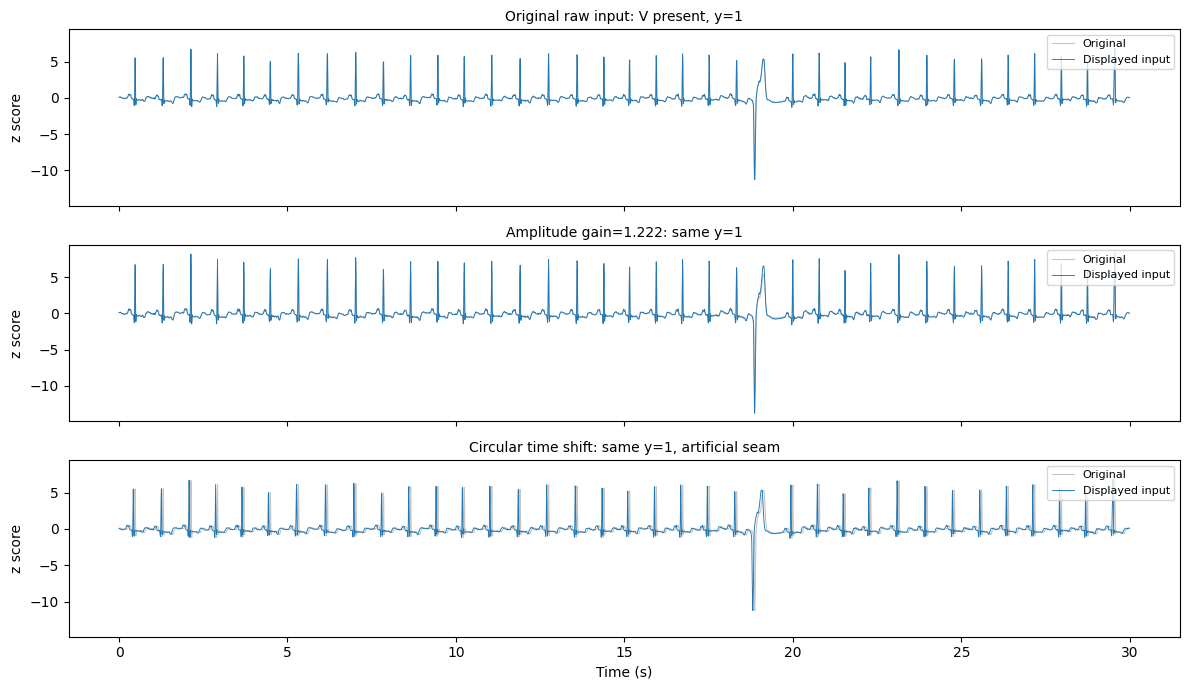

,gain,RMS_before,RMS_after,RMS_ratio
0,1.222001,1.0,1.222001,1.222001
1,1.223176,1.0,1.223176,1.223176


In [6]:
# 그림에서 사용할 예시와 증강을 고정합니다. 실제 실험은 뒤에서 SEEDS의 값을 다시 설정합니다.
seed_all(123)
# 양성 구간 하나와 음성 구간 하나를 고릅니다. pos/neg는 훈련 배열의 행 번호입니다.
tr=arrays['train']; pos=int(np.flatnonzero(tr['y']==1)[0]); neg=int(np.flatnonzero(tr['y']==0)[0])
# 이중 대괄호 [pos,neg]를 써 배치 축을 유지하므로 xx는 [2,1,3840]입니다.
xx=torch.from_numpy(tr['raw'][[pos,neg]])
yy=torch.from_numpy(tr['y'][[pos,neg]])
# force=True로 증강을 반드시 적용합니다. 두 NumPy generator는 그림 재현용으로 별도 생성합니다.
xa,ya,gain_info=apply_augmentation(xx,yy,'amplitude',np.random.default_rng(5),force=True)
xs,_,_=apply_augmentation(xx,yy,'shift',np.random.default_rng(6),force=True)
# sample 번호를 FS로 나눠 초 단위의 가로축으로 바꿉니다.
tt=np.arange(WINDOW_S*FS)/FS
# 같은 y축 범위를 사용해야 진폭이 커진 정도를 공정하게 눈으로 비교할 수 있습니다.
fig,axs=plt.subplots(3,1,figsize=(12,7),sharex=True,sharey=True)
for ax,z,title in zip(axs,[xx[0,0],xa[0,0],xs[0,0]],
 ['Original raw input: V present, y=1',
  f'Amplitude gain={gain_info["gains"][0]:.3f}: same y=1',
  'Circular time shift: same y=1, artificial seam']):
    ax.plot(tt,xx[0,0],color='gray',alpha=.45,lw=.8,label='Original')
    ax.plot(tt,z,lw=.65,label='Displayed input');ax.set_ylabel('z score');ax.set_title(title,fontsize=10)
    ax.legend(loc='upper right',fontsize=8)
axs[-1].set_xlabel('Time (s)');plt.tight_layout();plt.show()
# RMS=sqrt(mean(x²)). 양수 a를 전체 신호에 곱하면 RMS도 a배가 되어야 합니다.
rms_before=xx.square().mean(-1).sqrt().flatten()
rms_after=xa.square().mean(-1).sqrt().flatten()
display(pd.DataFrame({'gain':gain_info['gains'],'RMS_before':rms_before.numpy(),
                      'RMS_after':rms_after.numpy(),'RMS_ratio':(rms_after/rms_before).numpy()}))
# 정답을 유지했는지, 실제 RMS 비율이 뽑은 gain과 맞는지 확인합니다.
assert torch.equal(ya,yy)
assert torch.allclose(rms_after/rms_before,torch.tensor(gain_info['gains'],dtype=xx.dtype),atol=1e-5)


## 5. 2D 증강 시각화

가로는 0.5초 간격의 시간 프레임, 세로는 0.5Hz 간격의 주파수 빈입니다. 모든 패널에 같은 색 범위를 씁니다. Cutout은 12빈×6프레임(약 6Hz×3초), SpecAugment는 최대 8빈(4Hz)과 2프레임(1초)을 가립니다. center=True로 양 끝 반사 패딩을 사용하므로 프레임 중심은 0초부터 30초까지입니다. 마스킹 0은 각 log power 평면을 표준화한 평균입니다.

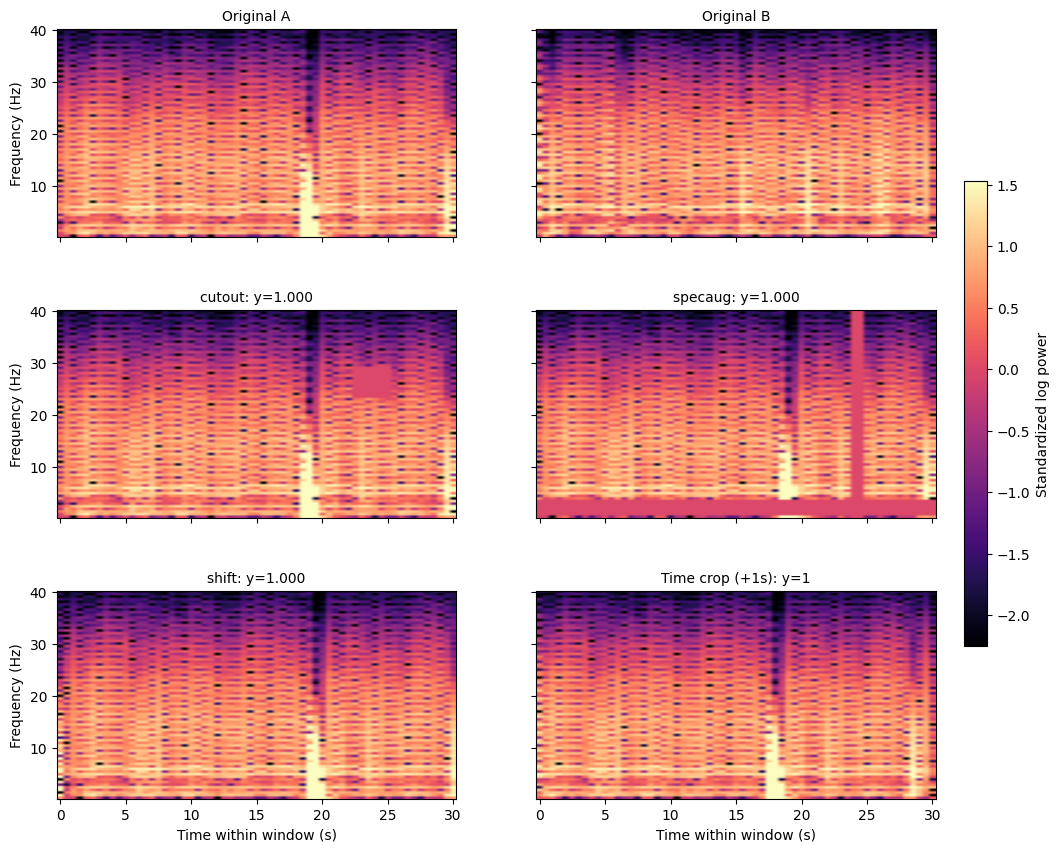

In [7]:
# 같은 두 훈련 구간의 2D 입력을 꺼냅니다. ss의 모양은 [2,1,80,61]입니다.
ss=torch.from_numpy(tr['spec'][[pos,neg]])
views=[('Original A',ss[0,0].numpy()),('Original B',ss[1,0].numpy())]
# 한 번에 한 종류만 적용해 원본과 비교합니다. force=True이므로 확률 게이트에서 건너뛰지
# 않습니다.
for kind in ['cutout','specaug','shift']:
    rng=np.random.default_rng(5)
    sx,sy,info=apply_augmentation(ss,yy,kind,rng,force=True)
    label=f'{kind}: y={float(sy[0]):.3f}'
    views.append((label,sx[0,0].numpy()))
# 마지막 후보 -1 인덱스는 시작점을 +1초 옮긴 30초 구간입니다. 그 후보의 새 정답도 제목에
# 표시합니다.
views.append((f'Time crop (+1s): y={tr["crop_y"][pos,-1]:g}',tr['crop_spec'][pos,-1,0]))
fig,axs=plt.subplots(3,2,figsize=(12,10),sharex=True,sharey=True)
# 모든 패널이 같은 색 범위를 쓰게 합니다. 색 차이를 각 그림의 자동 스케일 차이로 오해하지 않도록
# 합니다.
vmin,vmax=np.percentile(tr['spec'],[2,98])
for ax,(title,z) in zip(axs.flat,views):
    # origin=lower는 낮은 주파수를 아래에 둡니다. extent는 bin/프레임의 가장자리를 Hz/초로
    # 표시합니다.
    image=ax.imshow(z,origin='lower',aspect='auto',extent=[-.25,30.25,.25,40.25],
                    cmap='magma',vmin=vmin,vmax=vmax)
    ax.set_title(title,fontsize=10)
for ax in list(axs.flat)[len(views):]:ax.set_visible(False)
for ax in axs[-1]:ax.set_xlabel('Time within window (s)')
for ax in axs[:,0]:ax.set_ylabel('Frequency (Hz)')
fig.subplots_adjust(hspace=.35,right=.9)
# 색은 표준화한 log power입니다. mV나 절대 파워 눈금이 아닙니다.
fig.colorbar(image,ax=axs.ravel().tolist(),label='Standardized log power',fraction=.025,pad=.03)
plt.show()


### Crop은 정답도 함께 확인

가능하면 시작 위치 변경으로 y가 실제로 달라지는 창을 표시합니다. 파란 영역은 원래 창, 주황 선은 선택한 시간 crop의 시작·끝, 빨간 선은 V 주석입니다. 표시한 V 주석은 설명·라벨 생성에만 사용합니다.

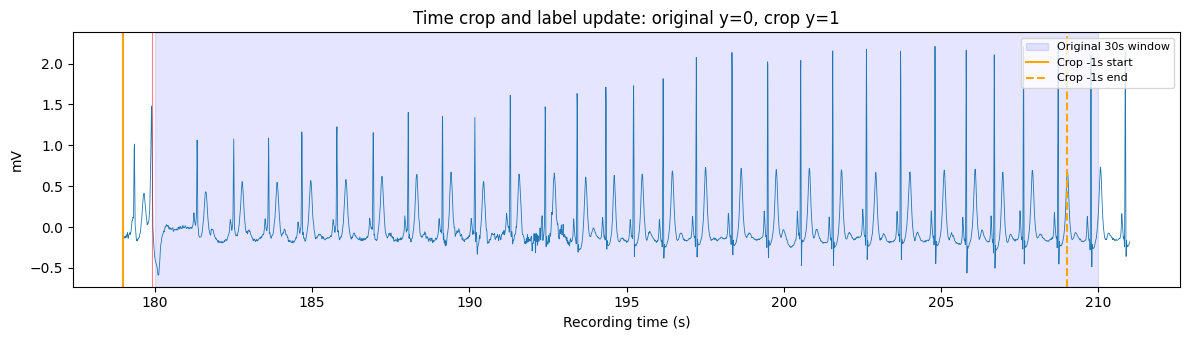

In [8]:
# crop으로 y가 달라지는 위치를 선택하고, 없으면 +1초 예시를 표시합니다.
# 다섯 crop 후보 중 하나라도 원래 정답과 달라지는 훈련 행을 찾습니다.
changed=np.flatnonzero(np.any(tr['crop_y']!=tr['y'][:,None],axis=1))
# 그런 구간이 있으면 첫 예시, 없으면 앞에서 고른 양성 예시를 사용합니다.
ci=int(changed[0]) if len(changed) else pos
different=np.flatnonzero(tr['crop_y'][ci]!=tr['y'][ci])
cj=int(different[0]) if len(different) else 4
crop_offset_s=float(np.array([-1,-.5,0,.5,1])[cj])
# meta의 행 순서는 훈련 배열과 맞춰 두었습니다. row에서 원래 창의 실제 기록 시각을 읽습니다.
row=tr['meta'].iloc[ci];record=str(row.record);x=signals[record]
fig,ax=plt.subplots(figsize=(12,3.5))
# 원래 창 앞뒤로 1초 문맥을 포함하되 기록의 범위를 넘지 않도록 제한합니다.
a=max(0,int((row.start_s-1)*FS));b=min(len(x),int((row.end_s+1)*FS))
ax.plot(np.arange(a,b)/FS,x[a:b],lw=.6)
ax.axvspan(row.start_s,row.end_s,alpha=.1,color='blue',label='Original 30s window')
# 화면의 시작점에도 데이터 준비 때와 같은 경계 제한을 적용합니다.
new_start=np.clip(int(row.start_s*FS)+int(crop_offset_s*FS),0,len(x)-WINDOW_S*FS)/FS
ax.axvline(new_start,color='orange',label=f'Crop {crop_offset_s:+g}s start')
ax.axvline(new_start+WINDOW_S,color='orange',ls='--',label=f'Crop {crop_offset_s:+g}s end')
# 빨간 V 시각은 설명용 표시입니다. 이 정보를 CNN 입력 채널로 넣지는 않습니다.
for vt in v_times[record]:
    if a/FS<=vt<b/FS:ax.axvline(vt,color='red',alpha=.5,lw=.8)
ax.set(title=f'Time crop and label update: original y={tr["y"][ci]:g}, crop y={tr["crop_y"][ci,cj]:g}',
       xlabel='Recording time (s)',ylabel='mV')
ax.legend(loc='upper right',fontsize=8);plt.tight_layout();plt.show()


## 6. 두 단일 CNN 구조

| 항목 | 1D CNN | 2D CNN |
|---|---|---|
| 입력 | 파형 B×1×3840 | 스펙트로그램 B×1×80×61 |
| 채널 | 8·16·24 | 8·16·32 |
| kernel | 15·7·5 | 7·5·3 |
| 정규화 | BatchNorm | GroupNorm4 |
| 축소 | 첫 Conv stride4, 앞 두 블록 MaxPool4 | 각 Conv stride2 |
| 끝부분 | Global average, Dropout0.2, Linear24→1 | Global average, Dropout0.2, Linear32→1 |

1D는 시간 파형을, 2D는 STFT 수치 배열을 처리합니다. 각 표현 안에서는 같은 입력 정규화·모델 구조·기록 분할을 유지하며 증강 조건을 비교합니다.

두 모델을 **각각 학습**하며 각 모델에서 sigmoid(logit)으로 V 포함 확률을 계산합니다. 마지막 단계에서 선택한 두 모델의 확률만 평균합니다. 새로운 결합 신경망은 학습하지 않습니다.

**모델을 읽는 순서:** `__init__`은 부품을 정의하고 `forward`는 입력이 지나가는 계산을 정의합니다. `embed`는 최종 판정 전의 특징 벡터를 반환합니다. `nn.AdaptiveAvgPool*`는 시간/공간 축을 평균해 고정 길이 특징을 만들고, `nn.Linear(...,1)`은 그 특징을 logit 하나로 바꿉니다.

1D의 주요 shape는 `[B,1,3840] → [B,8,960] → [B,8,240] → [B,16,60] → [B,24,60] → [B,24]`입니다. 2D는 `[B,1,80,61] → [B,8,40,31] → [B,16,20,16] → [B,32,10,8] → [B,32]`입니다. 마지막 두 모델 모두 `[B]` logit을 출력합니다.


In [9]:
# GroupNorm(그룹 수=4, 채널 수=channels). 각 샘플 안의 채널을 네 그룹으로 나눠 정규화합니다.
def gn(channels):
    return nn.GroupNorm(4,channels)

# 1D Conv는 시간 축을 따라 이동합니다. 여기서 출력 채널은 학습 필터 수이며 실제 ECG lead 수가
# 아닙니다.
class WaveEncoder(nn.Module):
    """처음 실습의 1D CNN: BatchNorm + MaxPool, 24차원 출력."""
    def __init__(self):
        super().__init__()
        # 입력 [B,1,3840] → 첫 Conv [B,8,960] → 첫 MaxPool [B,8,240].
        # 두 번째 Conv/Pool 후 [B,16,60], 세 번째 Conv 후 [B,24,60]입니다.
        # BatchNorm은 학습 중 배치 통계를 쓰며, 예측 시에는 저장된 running 통계를 사용합니다.
        self.blocks=nn.Sequential(
            nn.Conv1d(1,8,15,stride=4,padding=7),nn.BatchNorm1d(8),nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(8,16,7,padding=3),nn.BatchNorm1d(16),nn.ReLU(),nn.MaxPool1d(4),
            nn.Conv1d(16,24,5,padding=2),nn.BatchNorm1d(24),nn.ReLU())
        # 시간 축 전체를 평균해 [B,24,1]로 만든 뒤 Flatten으로 [B,24] 특징을 만듭니다.
        self.pool=nn.Sequential(nn.AdaptiveAvgPool1d(1),nn.Flatten())
    def forward(self,x):return self.pool(self.blocks(x))

# 2D Conv는 주파수와 시간 두 축을 함께 봅니다. 입력은 RGB 그림이 아닌 [B,1,80,61] 수치
# 배열입니다.
class SpecEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        layers=[];cin=1
        # 세 블록의 채널 수/커널 크기를 순서대로 짝짓습니다. stride=2로 두 축의 크기를 줄입니다.
        # 공간 크기는 80×61 → 40×31 → 20×16 → 10×8이고, 출력 채널은 8→16→32입니다.
        for cout,k in zip([8,16,32],[7,5,3]):
            layers += [nn.Conv2d(cin,cout,k,stride=2,padding=k//2,bias=False),gn(cout),nn.ReLU()]
            cin=cout
        self.blocks=nn.Sequential(*layers)
        # F/T 두 축을 평균해 [B,32,1,1], Flatten 후 [B,32] 특징을 얻습니다.
        self.pool=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten())
    def forward(self,x):return self.pool(self.blocks(x))

# nn.Module은 모델 부품의 가중치를 관리합니다. 1D/2D 중 고른 encoder 하나만 생성합니다.
class ECGClassifier(nn.Module):
    def __init__(self,representation):
        super().__init__();self.representation=representation
        # 함수 인수로 raw/spec를 둘 다 받더라도 여기서 선택한 한 가지 입력만 사용합니다. 특징
        # fusion 모델이 아닙니다.
        if representation=='1D':self.wave=WaveEncoder()
        if representation=='2D':self.spec=SpecEncoder()
        # 학습 중 특징의 일부를 확률 0.2로 가립니다. model.eval()에서는 Dropout을 끕니다.
        self.dropout=nn.Dropout(.2)
        # head는 24차원 또는 32차원 특징을 logit 하나로 바꾸는 선형층입니다.
        self.head=nn.Linear(24 if representation=='1D' else 32,1)
    def embed(self,raw,spec):
        if self.representation=='1D':return self.wave(raw)
        if self.representation=='2D':return self.spec(spec)
        raise ValueError(self.representation)
    # 출력 [B,1]을 squeeze(1)로 [B]로 바꿉니다. loss에는 sigmoid 전 logit을 넣습니다.
    def forward(self,raw,spec):return self.head(self.dropout(self.embed(raw,spec))).squeeze(1)

# 예시 두 구간으로 embedding/logit 모양과 파라미터 수를 확인합니다. 실제 학습은 다음 절에서 새
# 모델로 시작합니다.
for representation in ['1D','2D']:
    model=ECGClassifier(representation).eval()
    raw=torch.from_numpy(tr['raw'][:2]);spec=torch.from_numpy(tr['spec'][:2])
    with torch.no_grad():h=model.embed(raw,spec);logits=model(raw,spec)
    print(representation,'parameters=',sum(p.numel() for p in model.parameters()),
          'embedding=',tuple(h.shape),'logit=',tuple(logits.shape))


1D parameters= 3105 embedding= (2, 24) logit= (2,)
2D parameters= 8345 embedding= (2, 32) logit= (2,)


## 7. 공통 평가 도구

기준 지표는 **balanced accuracy(BAcc)**이며 양성 재현율과 음성 재현율의 평균입니다. AP·AUROC·F1·정밀도·재현율·특이도도 함께 계산합니다.

각 모델은 **검증 AP 최대 epoch**를 선택하고, 해당 모델의 **검증 BAcc 최대 임계값**을 선택합니다. 시험에서는 고정한 모델·임계값을 그대로 사용합니다. val/test에는 증강을 적용하지 않습니다.

같은 표현·같은 seed의 baseline과 증강 모델은 초기 가중치와 훈련 행 순서를 맞춥니다. 입력이 달라 학습 과정은 달라질 수 있습니다. 세 seed는 같은 환자 분할에서 최적화의 무작위성만 바꾸며, 환자 모집단의 불확실성을 평가하는 반복은 아닙니다.

최고 조건은 각 표현의 검증 AP를 3 seed에서 평균하여 선택합니다. 선택을 시험 평가 전에 저장하며, 앙상블의 확률 평균 가중치도 0.5:0.5로 고정합니다.

| 코드 표현 | 의미 |
|---|---|
| `torch.from_numpy(...)` | NumPy 배열을 tensor로 바꿉니다. |
| `.to(DEVICE)` | 입력과 모델을 같은 계산 장치에 놓습니다. |
| `model.train()` / `model.eval()` | BatchNorm·Dropout의 학습용/예측용 동작을 정합니다. |
| `torch.no_grad()` | 예측에서 gradient 계산 기록을 만들지 않습니다. |
| `state_dict()` | 가중치와 BatchNorm buffer 등을 이름과 함께 보관하는 사전입니다. |
| `.detach().cpu().clone()` | 계산 그래프에서 분리해 CPU에 독립 복사본을 남깁니다. |

`eval()` 자체가 가중치를 갱신하거나 고정하는 명령은 아닙니다. 실제 갱신은 학습 반복문에서 `loss.backward()` 다음 `optimizer.step()`이 수행합니다.


In [10]:
# Dataset은 __getitem__(i)로 구간 하나를 반환합니다. DataLoader가 이들을 모아 배치 축을
# 추가합니다.
class ECGDataset(Dataset):
    def __init__(self,part,crop=False):self.part=part;self.crop=crop
    def __len__(self):return len(self.part['y'])
    def __getitem__(self,i):
        # crop 조건의 train에서만 다섯 후보 중 하나를 샘플마다 선택합니다. 중심 후보(0초)도
        # 포함됩니다.
        if self.crop:
            # 입력 두 표현과 정답은 반드시 같은 후보 j를 사용합니다. crop 후 원래 y를 그대로
            # 쓰면 잘못된 라벨이 될 수 있습니다.
            j=int(torch.randint(5,(1,)).item())
            return (torch.from_numpy(self.part['crop_raw'][i,j]),
                    torch.from_numpy(self.part['crop_spec'][i,j]),torch.tensor(self.part['crop_y'][i,j]))
        # 일반 구간은 raw [1,3840], spec [1,80,61], scalar y를 반환합니다.
        return (torch.from_numpy(self.part['raw'][i]),torch.from_numpy(self.part['spec'][i]),
                torch.tensor(self.part['y'][i]))

# 예측용 Dataset은 crop=False이며 apply_pair도 호출하지 않습니다. val/test에 증강하지 않습니다.
# 이 함수의 representation 인수는 내부 계산에 직접 쓰이지 않습니다.
# 실제 입력 선택은 모델에 저장된 representation과 embed()에서 정합니다.
def predict(model,part,representation=None):
    loader=DataLoader(ECGDataset(part),batch_size=64,shuffle=False,num_workers=0)
    # eval은 BatchNorm/Dropout을 예측 모드로 바꿉니다. no_grad는 gradient 기록을 끄는 별도
    # 역할입니다.
    model.eval();scores=[]
    with torch.no_grad():
        for raw,spec,_ in loader:
            # 모델의 logit을 sigmoid로 0~1 점수로 바꿉니다. shuffle=False이므로 원래 meta의 행
            # 순서와 일치합니다.
            scores.extend(torch.sigmoid(model(raw.to(DEVICE),spec.to(DEVICE))).cpu().numpy())
    return np.asarray(scores)

# 점수 p와 임계값을 분리해 받습니다. AP/AUROC는 점수 순위, BAcc/F1 등은 판정 결과에 대한
# 지표입니다.
def metrics(y,p,threshold):
    y=np.asarray(y,dtype=int); pred=np.asarray(p)>=threshold
    # 혼동행렬 순서: 실제 음성을 맞힘(TN), 음성을 양성으로 오탐(FP), 양성을 놓침(FN), 양성을
    # 맞힘(TP).
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    # 한 종류의 정답만 있으면 이 실습에서는 AP/AUROC/BAcc를 NaN으로 표시합니다. 함수 실패를
    # 뜻하지 않습니다.
    both=len(np.unique(y))==2
    return {'AP':float(average_precision_score(y,p)) if both else np.nan,
        'AUROC':float(roc_auc_score(y,p)) if both else np.nan,
        'BAcc':float(balanced_accuracy_score(y,pred)) if both else np.nan,
        'F1':float(f1_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'precision':float(precision_score(y,pred,zero_division=0)),
        'specificity':float(tn/(tn+fp)) if tn+fp else np.nan,
        'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

# 여기에는 validation 정답과 점수를 넣습니다. test 점수로 이 함수를 다시 호출해 최적화하지
# 않습니다.
def choose_threshold(y,p):
    # 0.02~0.98의 97개 임계값을 비교합니다. 선택한 임계값은 test에서 고정합니다.
    candidates=np.linspace(.02,.98,97)
    # 검증 BAcc 최대. 동률이면 0.5에 가까운 값, 다시 동률이면 작은 값을 선택합니다.
    return float(max(candidates,key=lambda t:(metrics(y,p,t)['BAcc'],-abs(t-.5),-t)))


# 증강 조합을 모두 섞는 실험이 아닙니다. 각 조건은 none 또는 한 종류의 증강만 사용하는
# 비교입니다.
EXPERIMENTS=[('1D','none'),('1D','amplitude'),('1D','shift'),
             ('2D','none'),('2D','cutout'),
             ('2D','specaug'),('2D','shift'),('2D','crop')]


## 8. 전체 조건 학습

AdamW, 동일 epoch·배치 크기·학습률·weight decay·dropout을 사용합니다. 클래스 가중치는 훈련 음성 수/양성 수이며 BCEWithLogitsLoss에 사용합니다. 모든 증강 조건에서 0/1 정답을 사용합니다. 진폭 조절와 시간 이동은 정답을 유지하고 crop은 새 구간 주석으로 정답을 재계산합니다.

검증 AP가 개선될 때 체크포인트를 저장합니다. 다음 셀의 마지막까지는 시험 성능을 계산하지 않습니다. 실행 중 조건별 진행 상황을 출력하고 결과를 계속 저장합니다.

증강은 새로운 독립 환자를 만드는 것이 아닙니다. 학습 입력의 변형을 통해 모델이 특정 모양이나 위치에 지나치게 의존하는 것을 줄이려는 방법입니다. 이득을 보장하지 않습니다.

학습 반복문은 **gradient 비우기 → logit 계산 → loss 계산 → 역전파 → 가중치 갱신**으로 읽으면 됩니다. 그 뒤 validation에서 epoch를 선택합니다.

`pos_weight`는 train의 음성 수/양성 수입니다. 양성 라벨을 바꾸지 않고 양성 오차가 BCE loss에 미치는 비중을 조절합니다. `loss_sum`은 각 배치의 평균 loss에 그 배치의 크기를 곱해 합산하므로 마지막 배치가 작아도 epoch 평균을 올바르게 계산합니다.


In [11]:
# 모든 조건의 체크포인트와 임계값을 먼저 고정합니다. 여기서는 시험 자료를 사용하지 않습니다.
# run_records는 조건/seed마다 선택한 모델, history_rows는 모든 epoch의 학습 기록입니다.
run_records=[];history_rows=[]
# 바깥 반복문: 입력 표현과 증강 조건. 안쪽 반복문: 같은 조건을 세 seed에서 반복합니다.
for representation,augmentation in EXPERIMENTS:
    for seed in SEEDS:
        # 각 실행마다 seed를 다시 맞추고 새 모델을 생성합니다. 앞 실험의 학습 가중치를 이어받지
        # 않습니다.
        started=time.perf_counter();seed_all(seed)
        model=ECGClassifier(representation).to(DEVICE)
        # state_dict의 가중치와 buffer를 지문으로 남겨, 같은 표현/seed의 조건들이 같은
        # 초기값인지 확인합니다.
        initial_hash=hashlib.sha256(b''.join(v.cpu().numpy().tobytes() for v in model.state_dict().values())).hexdigest()
        # optimizer가 gradient를 받아 가중치를 갱신합니다. weight_decay는 가중치 크기를 규제하는
        # 설정입니다.
        optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=1e-3)
        # 클래스 가중치는 원래 30초 train 창의 음성/양성 비율로 계산합니다. validation/test의
        # 분포는 사용하지 않습니다.
        pos_count=float(tr['y'].sum());neg_count=len(tr['y'])-pos_count
        # BCEWithLogitsLoss 내부에 sigmoid 계산이 포함됩니다. 모델 출력에 sigmoid를 미리
        # 적용하지 않습니다.
        criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(neg_count/pos_count,device=DEVICE))
        # 셔플 전용 PyTorch generator를 같은 seed로 시작해 조건 간 훈련 행 순서를 맞춥니다.
        order_generator=torch.Generator().manual_seed(seed)
        # crop 조건이면 Dataset에서 후보 구간/라벨을 고릅니다. 다른 증강은 아래 apply_pair에서
        # 적용합니다.
        loader=DataLoader(ECGDataset(tr,crop=augmentation=='crop'),
            batch_size=BATCH_SIZE,shuffle=True,generator=order_generator,num_workers=0)
        # 증강에 사용할 NumPy 난수입니다. 매 epoch마다 새로 만들지 않고 이 실행 안에서 계속
        # 사용합니다.
        rng=np.random.default_rng(seed+1000)
        best_ap=-np.inf;best_state=None;best_epoch=None
        for epoch in range(1,EPOCHS+1):
            # train()은 BatchNorm 통계를 갱신하고 Dropout을 활성화합니다. 파라미터를 갱신하는
            # 것은 optimizer.step()입니다.
            model.train();loss_sum=0.;count=0
            for raw,spec,y in loader:
                # tensor를 모델과 같은 장치로 옮깁니다. y는 각 30초 구간의 0/1 float 정답입니다.
                raw,spec,y=raw.to(DEVICE),spec.to(DEVICE),y.to(DEVICE)
                # 선택한 표현에만 증강합니다. 진폭 조절/shift/masking은 y 유지, crop의 y는
                # Dataset에서 이미 갱신했습니다.
                raw,spec,y,_=apply_pair(raw,spec,y,representation,augmentation,rng)
                # 이전 미니배치의 gradient를 비웁니다. 이 실습은 gradient accumulation을 하지
                # 않습니다.
                optimizer.zero_grad(set_to_none=True)
                # forward로 logit을 계산하고 그 logit과 정답으로 loss를 구합니다.
                loss=criterion(model(raw,spec),y)
                # backward는 loss를 줄일 방향의 gradient를 계산하고, step은 실제 가중치를 한 번
                # 갱신합니다.
                loss.backward();optimizer.step()
                # 배치별 평균 loss에 배치 크기를 곱해 합산한 후 전체 표본 수로 나눠 epoch 평균을
                # 냅니다.
                loss_sum+=float(loss.detach())*len(raw);count+=len(raw)
            # epoch가 끝날 때 증강 없는 validation을 평가합니다. 여기서는 가중치를 업데이트하지
            # 않습니다.
            vp=predict(model,arrays['val'],representation)
            ap=average_precision_score(arrays['val']['y'],vp)
            history_rows.append({'representation':representation,'augmentation':augmentation,
                'seed':seed,'epoch':epoch,'train_loss':loss_sum/count,'val_AP':ap})
            # validation AP가 엄격히 더 좋아질 때만 best를 바꿉니다. 동률이면 먼저 선택한
            # epoch가 남습니다.
            if ap>best_ap:
                best_ap=float(ap);best_epoch=epoch
                # detach로 계산 그래프에서 분리하고 CPU에 옮긴 뒤 clone으로 독립 복사합니다.
                # clone이 있어야 이후 학습이 best_state의 내용을 덮어쓰지 않습니다. BatchNorm
                # buffer도 함께 보관합니다.
                best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        # 마지막 epoch가 아니라 선택된 best epoch의 가중치/BatchNorm 통계를 복원한 뒤 임계값을
        # 구합니다.
        model.load_state_dict(best_state)
        vp=predict(model,arrays['val'],representation)
        threshold=choose_threshold(arrays['val']['y'],vp)
        # 체크포인트는 표현·증강·seed마다 다른 파일로 저장합니다. 같은 조건의 세 seed는 별도
        # 모델입니다.
        path=OUT/f'{representation}_{augmentation}_seed{seed}.pt'
        # 가중치만이 아니라 표현 종류, 정규화 설정, 임계값도 함께 보관해야 같은 입력 처리로
        # 재사용할 수 있습니다.
        torch.save({'state_dict':best_state,'representation':representation,
                    'augmentation':augmentation,'seed':seed,'threshold':threshold,
                    'norm':norm,'config':CONFIG,'best_epoch':best_epoch},path)
        run_records.append({'representation':representation,'augmentation':augmentation,'seed':seed,
            'best_epoch':best_epoch,'val_AP':best_ap,'threshold':threshold,
            'training_seconds':time.perf_counter()-started,'initial_hash':initial_hash,
            'checkpoint':str(path),'parameters':sum(p.numel() for p in model.parameters())})
        print(f'{representation:2s} {augmentation:7s} seed={seed} val AP={best_ap:.3f} '
              f'epoch={best_epoch} t={threshold:.2f} seconds={time.perf_counter()-started:.1f}',flush=True)
        pd.DataFrame(run_records).to_csv(OUT/'frozen_validation_choices.csv',index=False)
        pd.DataFrame(history_rows).to_csv(OUT/'learning_curves.csv',index=False)
# 24개 실행의 선택 정보를 표로 모읍니다. 아래 assert는 조건 간 초기값 정렬을 확인합니다.
choices=pd.DataFrame(run_records)
assert choices.groupby(['representation','seed']).initial_hash.nunique().eq(1).all()
print('모든 조건의 선택을 고정했습니다. 이제 시험 자료를 평가합니다.')
# 표현별 최고 조건을 검증 AP의 seed 평균으로 선택합니다. 시험 점수는 사용하지 않습니다.
# 최고 조건 선택 기준은 test 점수가 아니라 각 조건의 validation AP를 세 seed에서 평균한
# 값입니다.
condition_validation=choices.groupby(['representation','augmentation'],sort=False).val_AP.mean()
# 1D와 2D에서 각각 증강 조건 하나를 고릅니다. seed 하나를 최고 모델로 뽑는 과정은 아닙니다.
best_conditions={rep:condition_validation.loc[rep].idxmax() for rep in ['1D','2D']}
(OUT/'selected_conditions.json').write_text(json.dumps(best_conditions,indent=2),encoding='utf-8')
display(condition_validation.rename('mean_validation_AP').to_frame())
print('검증으로 선택한 최고 조건:',best_conditions)

choices.to_csv(OUT/"frozen_validation_choices.csv",index=False)
pd.DataFrame(history_rows).to_csv(OUT/"learning_curves.csv",index=False)


1D none    seed=11 val AP=0.775 epoch=2 t=0.65 seconds=9.3
1D none    seed=22 val AP=0.684 epoch=7 t=0.92 seconds=2.2
1D none    seed=33 val AP=0.733 epoch=8 t=0.85 seconds=1.8
1D amplitude seed=11 val AP=0.771 epoch=1 t=0.57 seconds=1.8
1D amplitude seed=22 val AP=0.682 epoch=1 t=0.72 seconds=1.8
1D amplitude seed=33 val AP=0.749 epoch=8 t=0.85 seconds=1.8
1D shift   seed=11 val AP=0.756 epoch=2 t=0.67 seconds=1.9
1D shift   seed=22 val AP=0.668 epoch=1 t=0.72 seconds=2.5
1D shift   seed=33 val AP=0.729 epoch=2 t=0.42 seconds=2.1
2D none    seed=11 val AP=0.867 epoch=8 t=0.68 seconds=1.8
2D none    seed=22 val AP=0.876 epoch=8 t=0.22 seconds=1.7
2D none    seed=33 val AP=0.832 epoch=7 t=0.81 seconds=1.7
2D cutout  seed=11 val AP=0.871 epoch=8 t=0.72 seconds=1.7
2D cutout  seed=22 val AP=0.842 epoch=8 t=0.19 seconds=1.8
2D cutout  seed=33 val AP=0.826 epoch=7 t=0.75 seconds=2.3
2D specaug seed=11 val AP=0.877 epoch=8 t=0.69 seconds=2.1
2D specaug seed=22 val AP=0.864 epoch=6 t=0.37 sec

mean_validation_AP
representation augmentation                    
1D             none                    0.730472
               amplitude               0.733995
               shift                   0.717647
2D             none                    0.858129
               cutout                  0.846341
               specaug                 0.851395
               shift                   0.861840
               crop                    0.861702

검증으로 선택한 최고 조건: {'1D': 'amplitude', '2D': 'shift'}


## 9. 고정한 모든 조건을 시험 자료에서 평가

각 조건을 미리 정한 ablation으로 보고합니다. 시험에서 가장 좋아 보이는 조건만 골라서 결론 내리지 않습니다. 다음 연구에서 그 조건을 채택하려면 새로운 독립 시험이 필요합니다.

`delta_BAcc`와 `delta_AP`는 **같은 seed·같은 CNN의 무증강 기준선 대비 차이**입니다. +0.03은 BAcc가 3%포인트 높아졌다는 뜻입니다. 평균±표준편차는 seed 간 변동이며 환자 단위 신뢰구간이 아닙니다.

In [12]:
# 선택이 고정된 모델들의 test 평가입니다. 지표 한 행, 구간별 예측, 기록별 지표를 따로 모읍니다.
result_rows=[];prediction_frames=[];record_rows=[]
for r in run_records:
    # 저장한 조건과 동일한 CNN 구조를 새로 만든 뒤 선택된 checkpoint를 읽습니다.
    model=ECGClassifier(r['representation']).to(DEVICE)
    saved=torch.load(r['checkpoint'],map_location='cpu',weights_only=False)
    # 가중치뿐 아니라 BatchNorm의 running 통계 등도 복원합니다.
    model.load_state_dict(saved['state_dict'])
    # test에는 증강을 적용하지 않으며 저장된 validation 임계값으로 판정합니다.
    p=predict(model,arrays['test'],r['representation'])
    row={**r,**metrics(arrays['test']['y'],p,r['threshold'])}
    result_rows.append(row)
    # 같은 행 순서의 meta에 점수와 판정을 붙여 어떤 구간에서 오류가 났는지 추적합니다.
    pf=arrays['test']['meta'].copy();pf['score']=p;pf['prediction']=(p>=r['threshold']).astype(int)
    for key in ['representation','augmentation','seed']:pf[key]=r[key]
    prediction_frames.append(pf)
    # 전체 test 지표와 함께 기록별 성능도 봅니다. 한 종류 정답만 있는 기록의 일부 지표는
    # NaN입니다.
    for record,g in pf.groupby('record'):
        record_rows.append({k:r[k] for k in ['representation','augmentation','seed']}|
            {'record':record}|metrics(g.target,g.score,r['threshold']))
results=pd.DataFrame(result_rows)
predictions=pd.concat(prediction_frames,ignore_index=True)
record_results=pd.DataFrame(record_rows)
# 무증강 결과를 같은 표현/seed의 기준선으로 붙입니다. 서로 다른 seed끼리 빼는 비교가 아닙니다.
baselines=results.loc[results.augmentation.eq('none'),['representation','seed','BAcc','AP']].rename(
    columns={'BAcc':'baseline_BAcc','AP':'baseline_AP'})
# many_to_one 검사는 여러 증강 조건에 대응하는 baseline이 각 표현/seed마다 하나인지 확인합니다.
results=results.merge(baselines,on=['representation','seed'],validate='many_to_one')
# 예: 0.85 - 0.80 = +0.05는 BAcc +5%포인트입니다. 상대적인 5% 증가라는 뜻은 아닙니다.
results['delta_BAcc']=results.BAcc-results.baseline_BAcc
results['delta_AP']=results.AP-results.baseline_AP
# 조건별로 세 seed를 평균하고 표준편차를 계산합니다. 환자를 다시 뽑아 만든 신뢰구간은 아닙니다.
summary=results.groupby(['representation','augmentation'],sort=False).agg(
    runs=('seed','size'),BAcc_mean=('BAcc','mean'),BAcc_std=('BAcc','std'),
    AP_mean=('AP','mean'),AP_std=('AP','std'),AUROC_mean=('AUROC','mean'),
    F1_mean=('F1','mean'),recall_mean=('recall','mean'),specificity_mean=('specificity','mean'),
    delta_BAcc_mean=('delta_BAcc','mean'),delta_BAcc_std=('delta_BAcc','std'),
    delta_AP_mean=('delta_AP','mean'))
display(summary.round(4))
results.to_csv(OUT/'all_runs.csv',index=False)
summary.to_csv(OUT/'augmentation_comparison.csv')
predictions.to_csv(OUT/'test_predictions_all.csv',index=False)
record_results.to_csv(OUT/'test_metrics_by_record.csv',index=False)


runs  BAcc_mean  BAcc_std  AP_mean  AP_std  \
representation augmentation                                               
1D             none             3     0.9489    0.0482   0.9963  0.0056   
               amplitude        3     0.9204    0.0751   0.9920  0.0019   
               shift            3     0.7905    0.2748   0.9699  0.0499   
2D             none             3     0.9449    0.0250   0.9966  0.0012   
               cutout           3     0.9248    0.0264   0.9945  0.0009   
               specaug          3     0.7825    0.2406   0.9926  0.0046   
               shift            3     0.8825    0.1021   0.9923  0.0063   
               crop             3     0.8998    0.0940   0.9953  0.0021   

                             AUROC_mean  F1_mean  recall_mean  \
representation augmentation                                     
1D             none              0.9967   0.9526       0.9283   
               amplitude         0.9868   0.9437       0.9381   
               shift             0.9232   0.8920       0.9311   
2D             none              0.9929   0.9644       0.9677   
               cutout            0.9885   0.9534       0.9634   
               specaug           0.9836   0.9019       0.9789   
               shift             0.9831   0.9380       0.9733   
               crop              0.9903   0.9439       0.9662   

                             specificity_mean  delta_BAcc_mean  \
representation augmentation                                      
1D             none                    0.9694           0.0000   
               amplitude               0.9028          -0.0284   
               shift                   0.6500          -0.1583   
2D             none                    0.9222           0.0000   
               cutout                  0.8861          -0.0202   
               specaug                 0.5861          -0.1624   
               shift                   0.7917          -0.0625   
               crop                    0.8333          -0.0451   

                             delta_BAcc_std  delta_AP_mean  
representation augmentation                                 
1D             none                  0.0000         0.0000  
               amplitude             0.0736        -0.0043  
               shift                 0.3106        -0.0263  
2D             none                  0.0000         0.0000  
               cutout                0.0188        -0.0021  
               specaug               0.2416        -0.0039  
               shift                 0.0772        -0.0043  
               crop                  0.0755        -0.0012

## 10. 증강 전후 성능 시각화

첫 그림은 절대 BAcc, 두 번째는 같은 seed baseline과의 차이입니다. 음수인 막대도 그대로 표시합니다. 조건별 AP·AUROC·F1과 특이도를 위 표에서 함께 봅니다. 시험 자료에 겹치는 창이 있으므로 독립 표본으로 간주한 유의성 검정을 하지 않습니다.

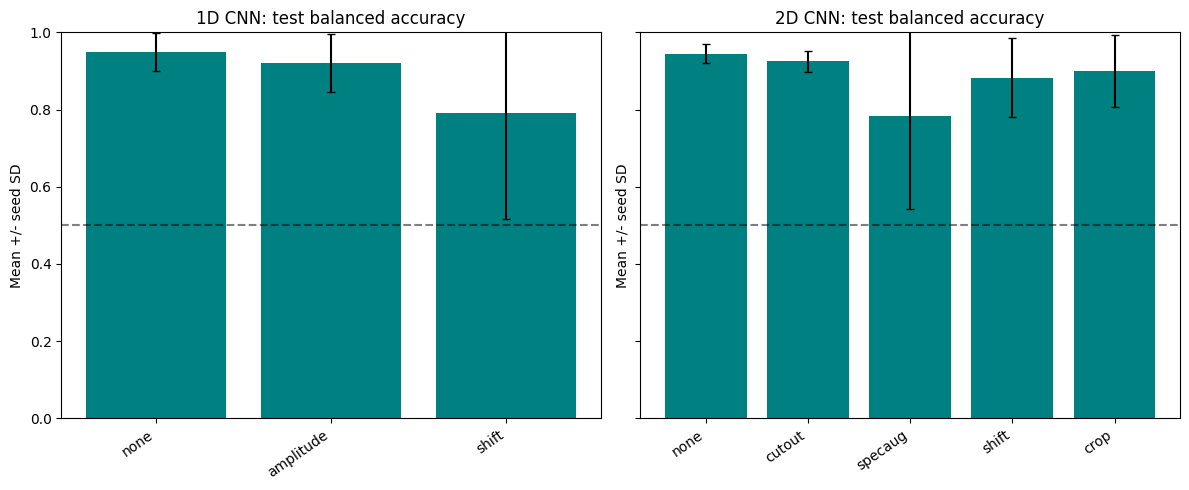

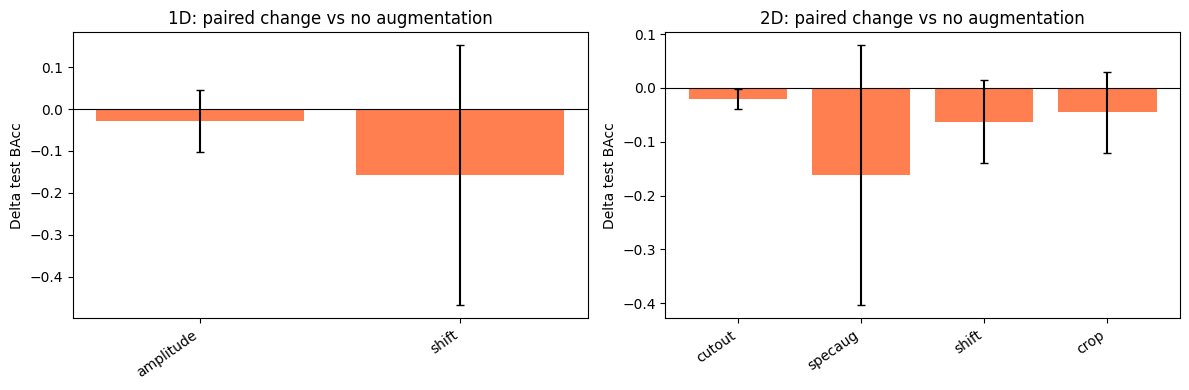

In [13]:
# 왼쪽/오른쪽에 1D와 2D 조건을 나눠 그립니다. 막대는 평균, 오차 막대는 seed 간 표준편차입니다.
fig,axs=plt.subplots(1,2,figsize=(12,5),sharey=True)
for ax,rep in zip(axs,['1D','2D']):
    s=summary.loc[rep]
    ax.bar(np.arange(len(s)),s.BAcc_mean,yerr=s.BAcc_std.fillna(0),capsize=3,color='teal')
    # BAcc 0.5를 읽기 위한 기준선입니다. 실제 모델 선택은 앞서 validation으로 끝냈습니다.
    ax.axhline(.5,color='black',ls='--',alpha=.5)
    ax.set_xticks(np.arange(len(s)),s.index,rotation=35,ha='right')
    ax.set(title=f'{rep} CNN: test balanced accuracy',ylabel='Mean +/- seed SD',ylim=(0,1))
plt.tight_layout();plt.show()
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,rep in zip(axs,['1D','2D']):
    # 두 번째 그림은 무증강을 0으로 두고 증강으로 얼마나 변했는지 보여 줍니다.
    s=summary.loc[rep].drop('none')
    # 차이가 양수이면 teal, 음수이면 coral입니다. 나빠진 결과도 숨기지 않고 같은 축에
    # 표시합니다.
    ax.bar(np.arange(len(s)),s.delta_BAcc_mean,yerr=s.delta_BAcc_std.fillna(0),capsize=3,
           color=['teal' if v>=0 else 'coral' for v in s.delta_BAcc_mean])
    ax.axhline(0,color='black',lw=.8)
    ax.set_xticks(np.arange(len(s)),s.index,rotation=35,ha='right')
    ax.set(title=f'{rep}: paired change vs no augmentation',ylabel='Delta test BAcc')
plt.tight_layout();plt.show()


### 결과 해석

무증강 대비 변화는 같은 seed·같은 CNN 안에서 비교합니다. 각 표현 안에서는 입력 전처리와 CNN 구조를 유지하고 증강 조건만 달리 비교합니다. seed 표준편차는 최적화 변동성이며 환자 모집단의 신뢰구간이 아닙니다. 시험 환자는 3명입니다.

앙상블에 사용할 조건은 **시험 BAcc가 아니라 검증 AP 평균**으로 고릅니다. 따라서 시험에서 가장 높아 보이는 조건과 선택 조건이 다를 수 있습니다. 증강이 항상 성능을 높이지는 않습니다.


## 11. 학습 곡선과 기록별 차이

훈련 loss와 검증 AP는 `learning_curves.csv`에 저장합니다. 아래에는 검증 AP 곡선을 표시합니다. 진폭 조절에서도 정답은 원래 0/1 라벨입니다. loss뿐 아니라 검증 AP와 환자별 오류도 함께 확인합니다.

기록별 표에서 한 사람의 모든 창이 양성 또는 음성이면 AP/AUROC·BAcc를 `NaN`으로 표시합니다. 이때 그 기록의 재현율·특이도 등 정의 가능한 지표와 혼동행렬을 확인합니다. 시험 환자가 3명뿐이므로 seed를 여러 번 반복해도 충분한 환자 일반화 검증이 되지는 않습니다.

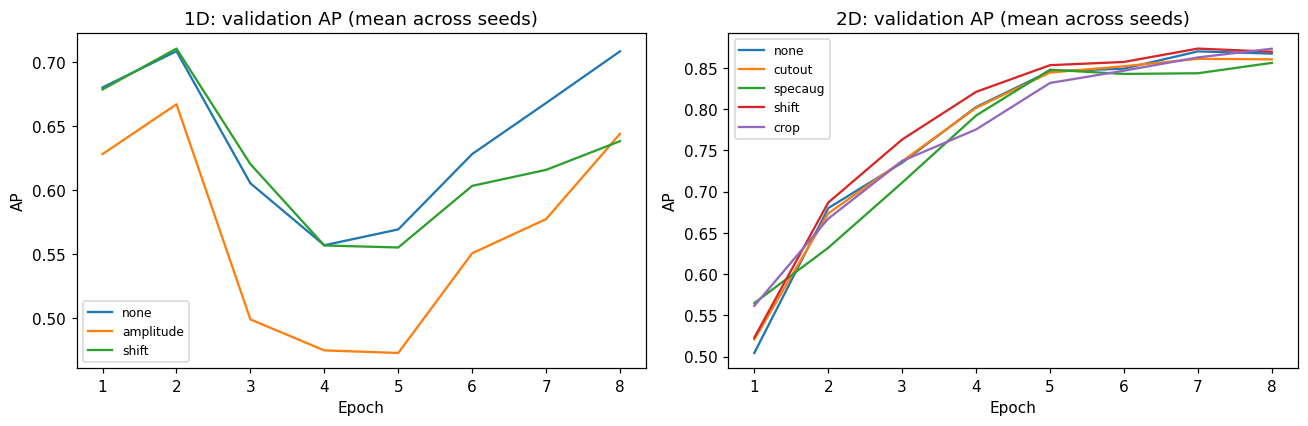

BAcc     AP  recall  specificity
representation augmentation record                                   
1D             none         117       NaN    NaN   0.000        0.964
                            203       NaN    NaN   0.924          NaN
                            208     0.661  0.995   0.989        0.333
               amplitude    117       NaN    NaN   0.000        0.913
                            203       NaN    NaN   0.905          NaN
                            208     0.819  0.996   0.972        0.667
               shift        117       NaN    NaN   0.000        0.972
                            203       NaN    NaN   0.913          NaN
                            208     0.661  0.995   0.989        0.333
2D             none         117       NaN    NaN   0.000        0.938
                            203       NaN    NaN   0.966          NaN
                            208     0.665  1.000   0.997        0.333
               cutout       117       NaN    NaN   0.000        0.899
                            203       NaN    NaN   0.950          NaN
                            208     0.665  1.000   0.997        0.333
               specaug      117       NaN    NaN   0.000        0.782
                            203       NaN    NaN   0.978          NaN
                            208     0.500  1.000   1.000        0.000
               shift        117       NaN    NaN   0.000        0.899
                            203       NaN    NaN   0.930          NaN
                            208     0.500  1.000   1.000        0.000
               crop         117       NaN    NaN   0.000        0.860
                            203       NaN    NaN   0.941          NaN
                            208     0.499  1.000   0.997        0.000

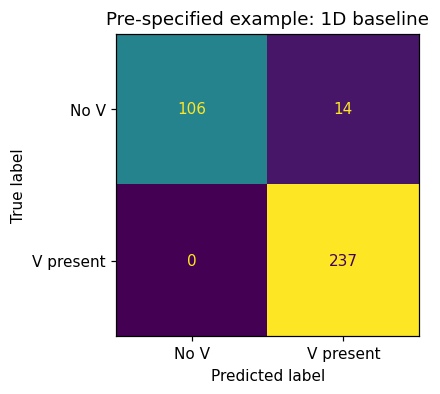

In [ ]:
# 각 조건/seed/epoch의 학습 기록을 표로 바꿉니다.
history=pd.DataFrame(history_rows)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,rep in zip(axs,['1D','2D']):
    for aug,g in history.loc[history.representation.eq(rep)].groupby('augmentation',sort=False):
        # 같은 epoch에서 세 seed의 validation AP를 평균한 곡선입니다. test AP 곡선이 아닙니다.
        line=g.groupby('epoch').val_AP.mean()
        ax.plot(line.index,line,label=aug)
    ax.set(title=f'{rep}: validation AP (mean across seeds)',xlabel='Epoch',ylabel='AP')
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()
# 기록별 평균도 확인합니다. 전체 평균이 좋아도 특정 기록에서는 성능이 낮을 수 있습니다.
display(record_results.groupby(['representation','augmentation','record'],sort=False)[
    ['BAcc','AP','recall','specificity']].mean().round(3))
# 시험 최고 조건을 고르지 않고, 미리 정한 1D baseline의 첫 seed 혼동행렬을 봅니다.
# 예시는 사전에 정한 1D 무증강·첫 seed입니다. test가 가장 좋은 모델을 찾아 보여 주는 과정이
# 아닙니다.
pf=predictions.query('representation == "1D" and augmentation == "none" and seed == @SEEDS[0]')
fig,ax=plt.subplots(figsize=(4,4))
ConfusionMatrixDisplay.from_predictions(pf.target,pf.prediction,labels=[0,1],
    display_labels=['No V','V present'],ax=ax,colorbar=False)
ax.set_title('Pre-specified example: 1D baseline');plt.tight_layout();plt.show()


## 12. 검증 최고 1D·2D 모델의 확률 평균 앙상블

앞에서 저장한 `best_conditions`를 그대로 사용합니다. 각 표현의 최고 조건은 **3 seed의 검증 AP 평균**으로 선택한 하나의 증강 조건입니다. 같은 seed로 학습한 1D·2D를 짝지어 세 번 비교합니다. 시험 점수로 조건을 재선택하거나 seed를 고르지 않습니다.

$$p_{ens}=0.5p_{1D}+0.5p_{2D}$$

각 단일 모델은 자기 검증 점수로 고른 임계값을 사용합니다. 앙상블은 **평균한 검증 점수**로 자체 임계값을 정하고 시험에 고정 적용합니다. 확률을 평균한 뒤 한 번 판정하므로, 0/1 판정의 평균이나 logit 평균과 다릅니다.

선택한 두 단일 모델과 앙상블의 BAcc·AP·AUROC·F1을 비교하고, 같은 seed의 개선량도 표시합니다. 두 모델의 오류가 비슷하거나 한 모델의 점수가 잘 보정되지 않으면 평균이 더 나쁠 수도 있습니다.

예를 들어 같은 구간에 1D가 0.2, 2D가 0.8을 출력하면 평균 점수는 0.5입니다. 이 값과 **앙상블 validation에서 고른 임계값**을 비교해 최종 0/1 판정을 합니다. 가중치 0.5/0.5를 test에 맞춰 조절하지 않습니다.


,runs,BAcc_mean,BAcc_std,AP_mean,AP_std,AUROC_mean,F1_mean
model,,,,,,,
1D,3,0.9246,0.0641,0.9923,0.0027,0.9876,0.9463
2D,3,0.9283,0.0574,0.9951,0.0047,0.9895,0.9558
Ensemble,3,0.9409,0.0705,0.9971,0.0022,0.9941,0.9676


model,1D,2D,Ensemble,delta_vs_1D,delta_vs_2D
seed,,,,,
11,0.8561,0.8623,0.8604,0.0043,-0.0019
22,0.9346,0.9559,0.9706,0.0360,0.0147
33,0.9832,0.9666,0.9917,0.0085,0.0251


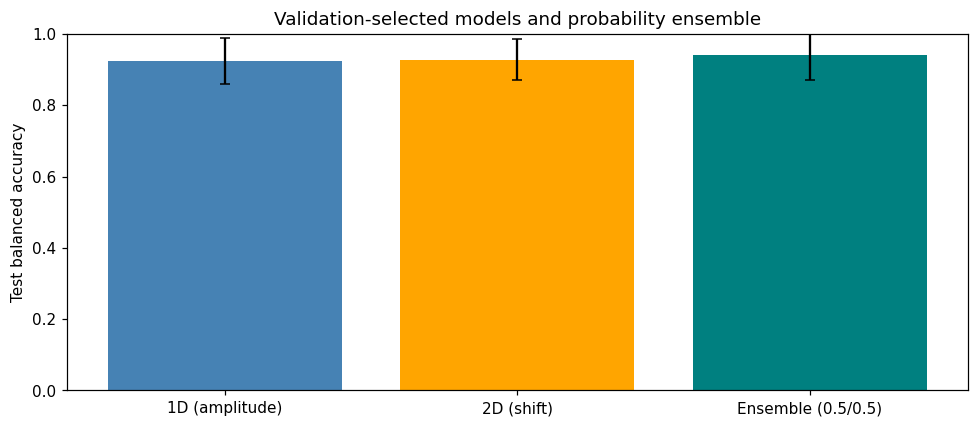

In [ ]:
# 여기서는 새 CNN을 학습하지 않습니다. 이미 선택한 두 단일 모델의 예측 점수만 결합합니다.
ensemble_rows=[];ensemble_predictions=[];selected_rows=[]
# 같은 seed의 1D와 2D를 한 쌍으로 묶습니다. 세 seed 전체를 한 번에 평균하는 방식이 아닙니다.
for seed in SEEDS:
    pair={}
    for rep in ['1D','2D']:
        # 앞서 validation AP의 seed 평균으로 고른 조건을 사용합니다. test를 보고 조건을 바꾸지
        # 않습니다.
        aug=best_conditions[rep]
        # 그 조건에서 현재 seed에 해당하는 checkpoint 한 개를 찾습니다.
        chosen=choices.loc[(choices.representation==rep)&(choices.augmentation==aug)&(choices.seed==seed)].iloc[0]
        model=ECGClassifier(rep).to(DEVICE)
        model.load_state_dict(torch.load(chosen.checkpoint,map_location='cpu',weights_only=False)['state_dict'])
        # validation 점수는 앙상블 임계값 선택용, test 점수는 마지막 평가용입니다. 둘을 분리해
        # 보관합니다.
        pair[rep]={'val':predict(model,arrays['val']),'test':predict(model,arrays['test'])}
        selected_rows.append({'model':rep,'augmentation':aug,'seed':seed,
            'threshold':chosen.threshold,**metrics(arrays['test']['y'],pair[rep]['test'],chosen.threshold)})
    # 1D와 2D가 같은 구간/행 순서를 예측하므로 원소별 평균을 낼 수 있습니다. 가중치 0.5는 미리
    # 고정했습니다.
    val_p=.5*pair['1D']['val']+.5*pair['2D']['val']
    # 단일 모델 임계값을 평균하지 않습니다. 평균한 validation 점수에서 앙상블의 임계값을 새로
    # 고릅니다.
    threshold=choose_threshold(arrays['val']['y'],val_p)
    # 확률 점수를 평균한 뒤 한 번 판정합니다. 두 0/1 판정의 평균이나 logit 평균이 아닙니다.
    test_p=.5*pair['1D']['test']+.5*pair['2D']['test']
    ensemble_rows.append({'model':'Ensemble','augmentation':'probability mean','seed':seed,
        'threshold':threshold,'val_AP':average_precision_score(arrays['val']['y'],val_p),
        **metrics(arrays['test']['y'],test_p,threshold)})
    pf=arrays['test']['meta'].copy();pf['seed']=seed;pf['score']=test_p
    pf['prediction']=(test_p>=threshold).astype(int);ensemble_predictions.append(pf)
ensemble_results=pd.DataFrame(ensemble_rows)
selected_results=pd.DataFrame(selected_rows)
comparison=pd.concat([selected_results,ensemble_results],ignore_index=True)
ensemble_comparison=comparison.groupby('model',sort=False).agg(
    runs=('seed','size'),BAcc_mean=('BAcc','mean'),BAcc_std=('BAcc','std'),
    AP_mean=('AP','mean'),AP_std=('AP','std'),AUROC_mean=('AUROC','mean'),F1_mean=('F1','mean'))
# 각 seed의 단일 모델 BAcc를 한 행에 모아 같은 seed의 앙상블과 차이를 계산합니다.
paired=selected_results.pivot(index='seed',columns='model',values='BAcc')
paired['Ensemble']=ensemble_results.set_index('seed').BAcc
# 단일 모델 하나보다 높은지와 두 단일 모델 모두보다 높은지는 다른 질문입니다. 두 차이를 함께
# 봅니다.
paired['delta_vs_1D']=paired.Ensemble-paired['1D']
paired['delta_vs_2D']=paired.Ensemble-paired['2D']
display(ensemble_comparison.round(4));display(paired.round(4))
comparison.to_csv(OUT/'selected_models_and_ensemble_runs.csv',index=False)
ensemble_comparison.to_csv(OUT/'ensemble_comparison.csv')
paired.to_csv(OUT/'ensemble_paired_change.csv')
pd.concat(ensemble_predictions).to_csv(OUT/'ensemble_predictions.csv',index=False)
# 마지막 그림의 오차 막대도 세 seed의 변동입니다. 앙상블의 우월성을 보장하는 신뢰구간은
# 아닙니다.
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(np.arange(3),ensemble_comparison.BAcc_mean,yerr=ensemble_comparison.BAcc_std.fillna(0),
       capsize=3,color=['steelblue','orange','teal'])
ax.set_xticks(np.arange(3),[f'1D ({best_conditions["1D"]})',f'2D ({best_conditions["2D"]})','Ensemble (0.5/0.5)'])
ax.set(ylabel='Test balanced accuracy',ylim=(0,1),title='Validation-selected models and probability ensemble')
plt.tight_layout();plt.show()


## 13. 결과 저장

`results/ecg_cnn_ensemble/`에 모델별 `.pt`, 전체 실험 CSV, 전후 비교 CSV, 기록별 성능, 학습 곡선, 데이터 manifest와 설정 JSON을 저장합니다. 모델 재사용에는 해당 입력 표현과 훈련 정규화 통계도 필요합니다. `.pt`는 신뢰하는 파일만 로드하세요.

저장된 체크포인트에는 모델 구조를 식별할 표현명과 정규화 설정을 포함합니다. 원신호를 입력하려면 동일 필터·128Hz resampling·30초 창 처리를 먼저 적용하고, 2D라면 동일 STFT를 계산해야 합니다.

In [ ]:
# 설정과 패키지 버전을 남겨 다른 실행 환경에서 결과를 해석할 때 참고합니다.
import importlib.metadata
# **CONFIG는 기존 설정을 펼쳐 새 dict에 넣는 문법입니다. 이어서 전처리/앙상블 설명을 추가합니다.
settings={**CONFIG,'normalization':norm,'device':str(DEVICE),'python':platform.python_version(),
    'packages':{p:importlib.metadata.version(p) for p in ['torch','numpy','scipy','pandas','wfdb','scikit-learn']},
    'reference':'sub_nh_1-main.zip: model_code.py EEGWindowCNN/SpectrogramFrontEnd/EEGSpectroCNN',
    'filter':'4th-order Butterworth .5-40Hz, sosfiltfilt full record, offline',
    'resampling':'scipy resample_poly 16/45, 360Hz to128Hz',
    'spectrum':'torch.stft fft256 hop64 center reflect .5-40Hz 80x61; per-plane zscore',
    'selection':'val AP checkpoint; best condition by mean val AP across 3 seeds; val BAcc threshold; no test selection',
    'ensemble':{'selected_conditions':best_conditions,'probability_weights':[.5,.5]},
    'amplitude':'raw only; per-window positive gain U(0.9,1.3), batch apply p=.7, after zscore, no re-standardization',
    'shift':'circular time only max .5s; artificial wrap boundary',
    'crop':'30s crop at offset {-1,-.5,0,.5,1}s from train record; labels recalculated',
    'cutout':'12 frequency bins x6 time frames, per-plane mean fill0',
    'specaug':'time mask up to1s and frequency mask up to4Hz; no time warp',
    # 원본 파일의 SHA256 지문을 저장합니다. 나중에 같은 데이터 파일을 사용했는지 비교할 수
    # 있습니다.
    'data_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest()
        for r in sum(SPLITS.values(),[]) for e in ['hea','dat','atr'] for p in [DATA/f'{r}.{e}']}}
# ensure_ascii=False는 한글을 그대로 저장하고, indent=2는 사람이 읽기 쉽게 들여쓰기합니다.
(OUT/'settings.json').write_text(json.dumps(settings,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saved:',OUT)
print('Rows:',len(meta),'conditions:',len(EXPERIMENTS),'training runs:',len(results))


Saved: /workspace/scratch/eddb7249d431/results/ecg_cnn_ensemble
Rows: 1428 conditions: 8 training runs: 24



**해설:** 시간 이동은 사건 위치를 바꾸고 주파수 이동은 생리적 진동 속도를 바꿉니다. crop은 새 구간의 정답을 재계산합니다. 가림은 사건 정보와 라벨을 어긋나게 할 수 있습니다. seed 변동성은 환자 일반화 불확실성과 다릅니다. 모델 선택과 임계값 결정에는 검증 자료를 사용합니다. 앙상블의 효과는 두 모델 오류의 상관성과 확률 보정에 영향을 받습니다.

## 참고 자료

- [MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/)
- DeVries & Taylor. [Cutout](https://arxiv.org/abs/1708.04552), 2017.
- Park et al. [SpecAugment](https://www.isca-archive.org/interspeech_2019/park19e_interspeech.html), Interspeech 2019.
- Lee et al. (2026) Late Fusion of Time-Domain and Time-Frequency Representations of Sleep EEG for Future Cognitive Impairment Prediction, CinC 2026의 EEG CNN·STFT 구조를 2D 설계에 참고함.
